# Lab 2.1 – Nhìn dữ liệu `segment` theo X và Y

Mục tiêu: hiểu cái biểu đồ chấm trong **UserClassifier** của Weka đang vẽ cái gì.

- **X** = `region-centroid-row`: vị trí dòng của vùng ảnh (số nhỏ = phía trên bức ảnh, số lớn = phía dưới)
- **Y** = `intensity-mean`: độ sáng trung bình của vùng ảnh (số lớn = sáng, số nhỏ = tối)
- **Màu** = `class`: đáp án thật (vùng đó là trời, cỏ, gạch, ...)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import arff

# Đổi đường dẫn này cho đúng máy bạn.
# File nằm sẵn trong thư mục data của Weka, ví dụ:
#   C:/Program Files/Weka-3-8-6/data/segment-challenge.arff
DUONG_DAN = "datasets/segment-challenge.arff"

# Màu giống hệt bên Weka để dễ so
MAU = {
    "brickface": "#1f3fd1",  # xanh dương đậm
    "sky":       "#e3261b",  # đỏ
    "foliage":   "#22c42a",  # xanh lá
    "cement":    "#2ad4e6",  # xanh nhạt
    "window":    "#f2a5b5",  # hồng nhạt
    "path":      "#e22be6",  # hồng tím
    "grass":     "#f5b800",  # vàng
}
X, Y = "region-centroid-row", "intensity-mean"


## Bước 1: Nạp file ARFF vào pandas

In [2]:
data, meta = arff.loadarff(DUONG_DAN)
df = pd.DataFrame(data)
df["class"] = df["class"].str.decode("utf-8")   # cột chữ bị đọc thành bytes, đổi lại thành chữ thường

print("Số dòng, số cột:", df.shape)
df.head()

Số dòng, số cột: (1500, 20)


,region-centroid-col,region-centroid-row,region-pixel-count,short-line-density-5,short-line-density-2,vedge-mean,vegde-sd,hedge-mean,hedge-sd,intensity-mean,rawred-mean,rawblue-mean,rawgreen-mean,exred-mean,exblue-mean,exgreen-mean,value-mean,saturation-mean,hue-mean,class
0,38.0,189.0,9.0,0.0,0.0,1.000000,0.222222,6.222220,33.318500,29.074100,26.333300,35.22220,25.6667,-8.22222,18.44440,-10.22220,35.22220,0.271208,-2.04915,path
1,25.0,199.0,9.0,0.0,0.0,1.111110,0.607407,1.055560,0.462963,17.518500,13.111100,17.88890,21.5556,-13.22220,1.11111,12.11110,21.55560,0.393002,2.69011,grass
2,49.0,139.0,9.0,0.0,0.0,0.166667,0.077778,0.333333,0.088889,0.444444,0.000000,1.33333,0.0000,-1.33333,2.66667,-1.33333,1.33333,0.777778,-2.09440,foliage
3,63.0,220.0,9.0,0.0,0.0,3.055560,15.263000,3.666670,6.088890,8.185190,6.555560,6.44444,11.5556,-4.88889,-5.22222,10.11110,11.55560,0.486717,2.09315,grass
4,161.0,135.0,9.0,0.0,0.0,0.055556,0.136083,0.111111,0.172133,1.259260,0.777778,3.00000,0.0000,-1.44444,5.22222,-3.77778,3.00000,1.000000,-1.82221,window


## Bước 2: Bỏ bớt cột, chỉ giữ X, Y và class

File gốc có 20 cột. Cái cây bạn khoanh trong Weka **chỉ dùng 2 cột** (region-centroid-row và intensity-mean),
17 cột còn lại không đụng tới, nên bỏ đi cho gọn.

In [3]:
df2 = df[[X, Y, "class"]]
df2.head(10)

,region-centroid-row,intensity-mean,class
0,189.0,29.074100,path
1,199.0,17.518500,grass
2,139.0,0.444444,foliage
3,220.0,8.185190,grass
4,135.0,1.259260,window
5,88.0,2.777780,foliage
6,32.0,126.222000,sky
7,182.0,58.000000,path
8,245.0,9.740740,grass
9,171.0,45.925900,path


In [4]:
# Mỗi class có bao nhiêu chấm?
df2["class"].value_counts()

class
path         236
sky          220
cement       220
foliage      208
grass        207
brickface    205
window       204
Name: count, dtype: int64

## Bước 3: Tách theo X và Y – mỗi class nằm ở khoảng nào?

Đọc bảng: ví dụ dòng **sky**, cột Y (intensity-mean) có min = 86 → nghĩa là
*mọi* mẫu sky đều sáng hơn 86, trong khi các class khác gần như đều tối hơn 80.
Đó là lý do khoanh sky dễ nhất.

In [5]:
bang = df2.groupby("class")[[X, Y]].agg(["min", "mean", "max"]).round(1)
bang

region-centroid-row               intensity-mean              
                          min   mean    max            min   mean    max
class                                                                   
brickface                40.0  102.6  149.0            3.8   14.7   28.6
cement                   15.0   98.8  162.0            4.9   44.5   72.9
foliage                  64.0  110.9  147.0            0.0    9.5   79.7
grass                   149.0  204.6  251.0            5.6   15.5   30.1
path                    159.0  186.4  210.0           23.6   49.3   63.2
sky                      11.0   46.6  115.0           86.3  118.6  143.4
window                   12.0  113.7  155.0            0.0    7.8   31.8

## Bước 4: Vẽ lại biểu đồ chấm giống Weka

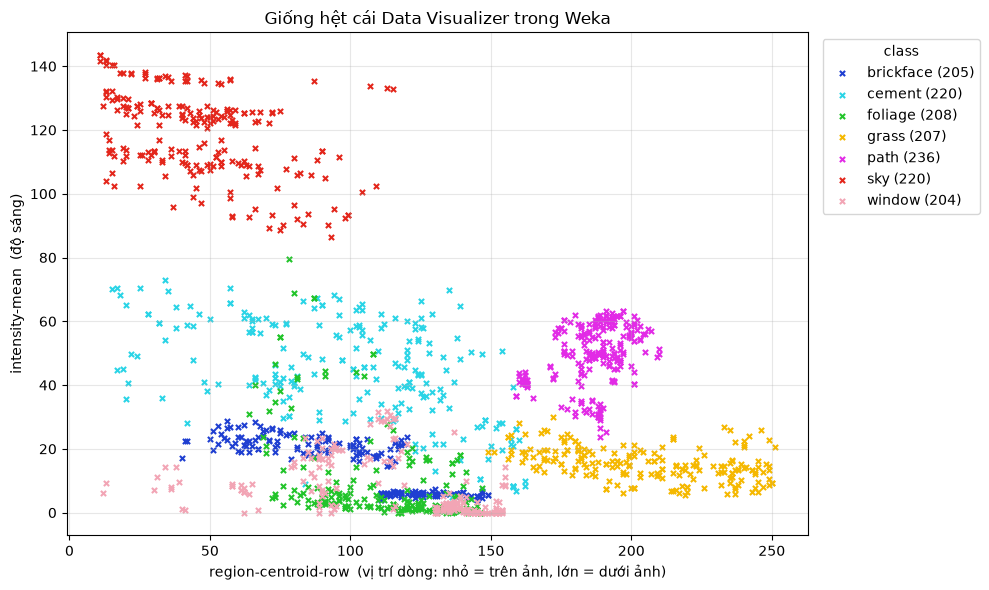

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))
for ten, nhom in df2.groupby("class"):
    ax.scatter(nhom[X], nhom[Y], s=14, marker="x", color=MAU[ten], label=f"{ten} ({len(nhom)})")
ax.set_xlabel(X + "  (vị trí dòng: nhỏ = trên ảnh, lớn = dưới ảnh)")
ax.set_ylabel(Y + "  (độ sáng)")
ax.set_title("Giống hệt cái Data Visualizer trong Weka")
ax.legend(title="class", bbox_to_anchor=(1.01, 1), loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Bước 5: Bar chart – giá trị trung bình của mỗi class theo X và theo Y

Hai biểu đồ đặt cạnh nhau: bên trái là X, bên phải là Y.
Cột nào **cao/thấp khác hẳn** các cột còn lại → class đó dễ tách theo trục đó.

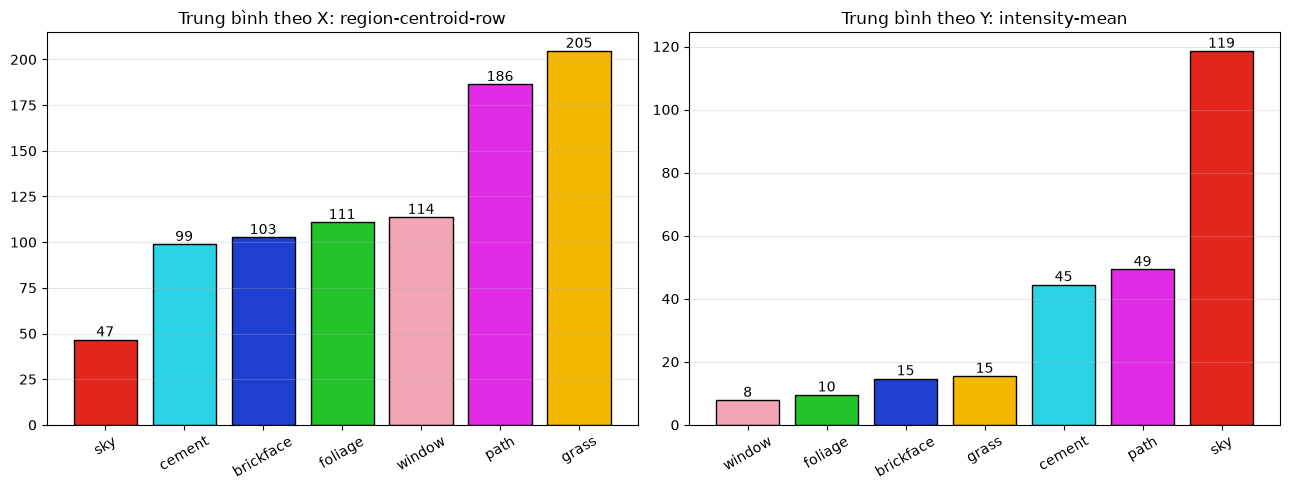

In [7]:
tb = df2.groupby("class")[[X, Y]].mean()
mau_cot = [MAU[c] for c in tb.index]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, cot, ten_truc in zip(axes, [X, Y], ["X: region-centroid-row", "Y: intensity-mean"]):
    thu_tu = tb[cot].sort_values()
    cot_ve = ax.bar(thu_tu.index, thu_tu.values, color=[MAU[c] for c in thu_tu.index], edgecolor="black")
    ax.bar_label(cot_ve, fmt="%.0f")
    ax.set_title("Trung bình theo " + ten_truc)
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Bước 6: Bar chart chồng – mỗi khoảng giá trị có những class nào?

Biểu đồ trung bình chưa cho thấy chuyện **chồng lấn**. Ở đây mình chia trục ra thành từng khúc,
rồi đếm mỗi khúc có bao nhiêu chấm của từng class. Khúc nào **nhiều màu chồng lên nhau** → khoanh chỗ đó kiểu gì cũng dính nhầm.

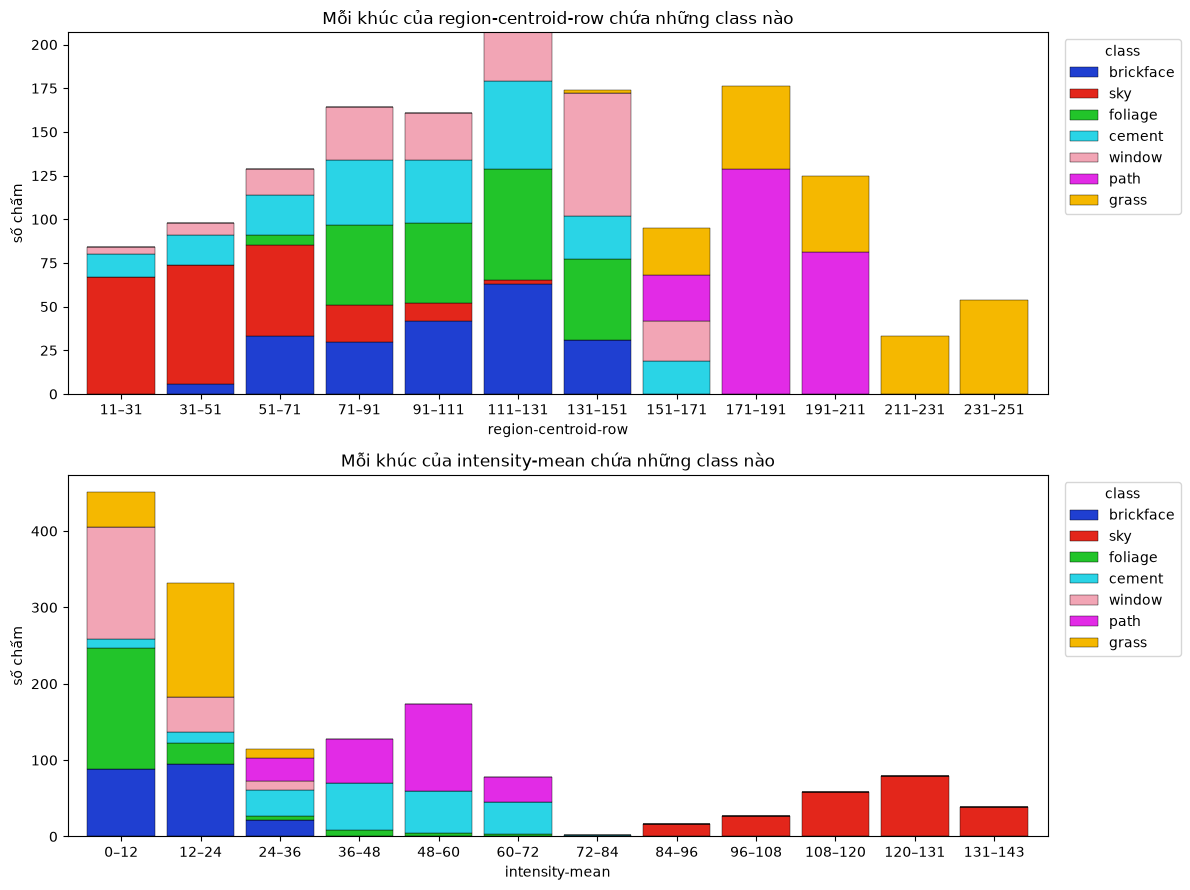

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 9))
for ax, cot, so_khuc in zip(axes, [X, Y], [12, 12]):
    khuc = pd.cut(df2[cot], bins=so_khuc)
    dem = pd.crosstab(khuc, df2["class"])[list(MAU)]   # đếm số chấm mỗi class trong mỗi khúc
    dem.index = [f"{max(k.left, 0):.0f}–{k.right:.0f}" for k in dem.index]
    dem.plot(kind="bar", stacked=True, ax=ax, color=[MAU[c] for c in dem.columns],
             edgecolor="black", linewidth=0.3, width=0.85)
    ax.set_title(f"Mỗi khúc của {cot} chứa những class nào")
    ax.set_xlabel(cot)
    ax.set_ylabel("số chấm")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title="class", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Rút ra gì?

- **sky**: chỉ cần nhìn Y là đủ, sáng hơn 86 là sky. Khoanh phát ăn liền.
- **grass, path**: nằm phía dưới ảnh (X lớn, khoảng 150–250). Grass tối, path sáng hơn → tách được.
- **brickface, foliage, window**: cùng nằm X khoảng 40–150, cùng tối (Y dưới 30). Trên biểu đồ chồng, các khúc này toàn màu xanh dương, xanh lá, hồng nhạt trộn chung → **không có cách khoanh nào tách sạch**.
- Đó chính là lý do trong kết quả Weka của bạn, **49 mẫu window và 30 mẫu foliage bị đoán thành brickface**, và tại sao **không thể làm cây "hoàn hảo"** chỉ với 2 cột này.